# Exploratory Data Analysis
## Predictive Modeling and Risk Scoring for Bank Customer Churn

### Objective
Explore customer characteristics, understand churn distribution,
identify patterns, and investigate relationships between customer
attributes and churn behavior.

### Dataset
European Bank Customer Dataset

### Target Variable
Exited:
- 0 = Customer retained
- 1 = Customer churned

### Analysis Sections
1. Dataset Overview
2. Descriptive Statistics
3. Target Variable Analysis
4. Univariate Analysis
5. Bivariate Analysis
6. Multivariate Analysis
7. Correlation Analysis
8. Key Findings and Business Insights

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization configuration
sns.set_theme(style="whitegrid")

# Load the original dataset
df = pd.read_csv("../data/raw/european-bank.csv")

print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape}")

Dataset loaded successfully.
Dataset shape: (10000, 14)


In [2]:
print("========== FIRST FIVE RECORDS ==========")
display(df.head())

print("\n========== LAST FIVE RECORDS ==========")
display(df.tail())

print("\n========== DATASET INFORMATION ==========")
df.info()

print("\n========== DATASET DIMENSIONS ==========")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())

========== FIRST FIVE RECORDS ==========


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



========== LAST FIVE RECORDS ==========


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,2025,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,2025,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,2025,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,2025,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,2025,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0



========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

========== DATASET DIMENSIONS ==========
Rows: 100

In [3]:
print("========== NUMERICAL DESCRIPTIVE STATISTICS ==========")

display(df.describe())

print("\n========== ALL COLUMN DESCRIPTIVE STATISTICS ==========")

display(df.describe(include="all"))

========== NUMERICAL DESCRIPTIVE STATISTICS ==========


,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,2025.0,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,2025.0,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



========== ALL COLUMN DESCRIPTIVE STATISTICS ==========


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000,10000.000000,10000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
unique,NaN,NaN,2932,NaN,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Smith,NaN,France,Male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,32,NaN,5014,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2025.0,1.569094e+07,NaN,650.528800,NaN,NaN,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,NaN,96.653299,NaN,NaN,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,NaN,350.000000,NaN,NaN,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,NaN,584.000000,NaN,NaN,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,NaN,652.000000,NaN,NaN,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,NaN,718.000000,NaN,NaN,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000


In [4]:
target_counts = df["Exited"].value_counts().sort_index()

target_percentages = (
    df["Exited"].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    "Customer Count": target_counts,
    "Percentage": target_percentages
})

target_summary.index = ["Retained (0)", "Churned (1)"]

display(target_summary)

,Customer Count,Percentage
Retained (0),7963,79.63
Churned (1),2037,20.37


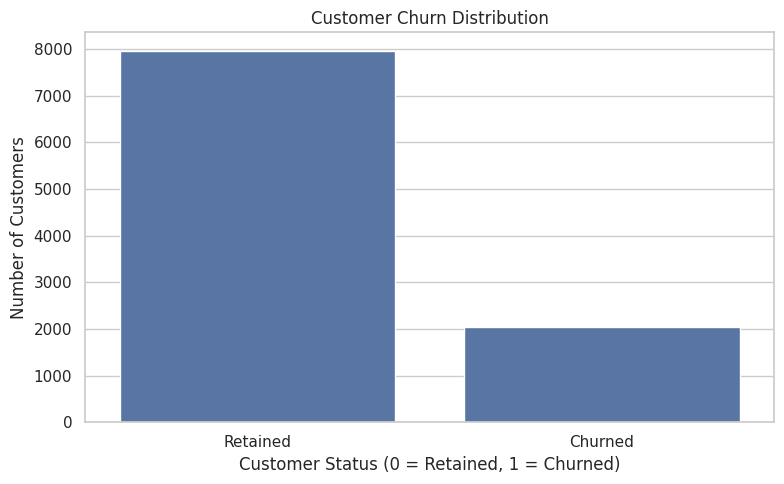

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Exited"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["Retained", "Churned"])

plt.tight_layout()
plt.show()

## 4. Univariate Analysis

### 4.1 Numerical Feature Distributions

Analyze the distributions of numerical customer attributes using
histograms and boxplots.

Features:
- CreditScore
- Age
- Tenure
- Balance
- NumOfProducts
- EstimatedSalary

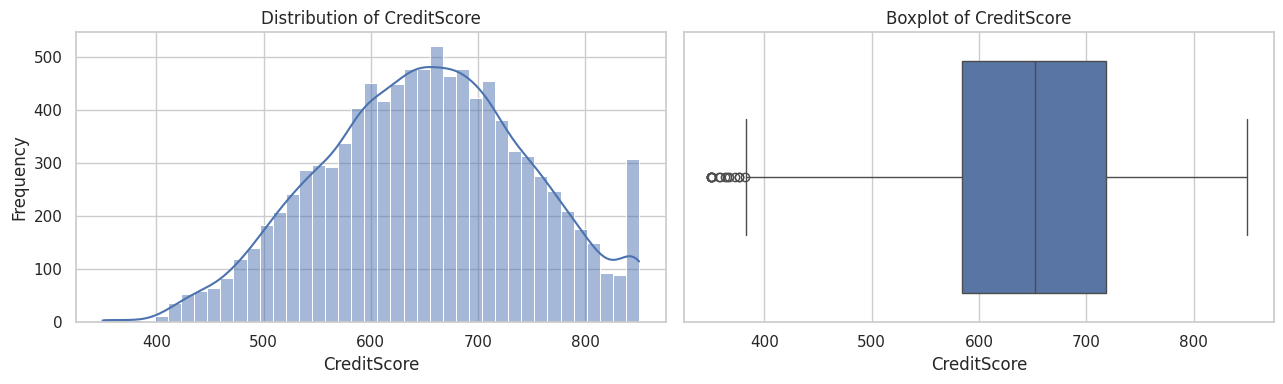

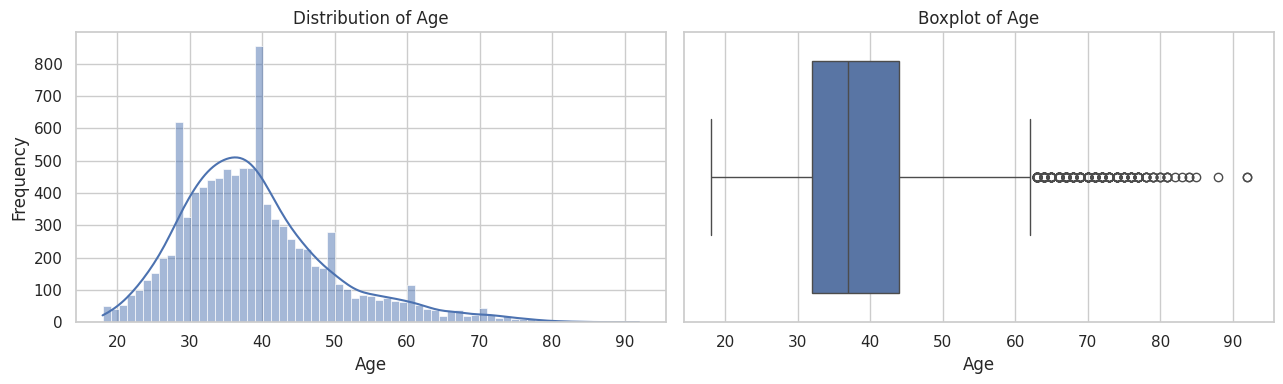

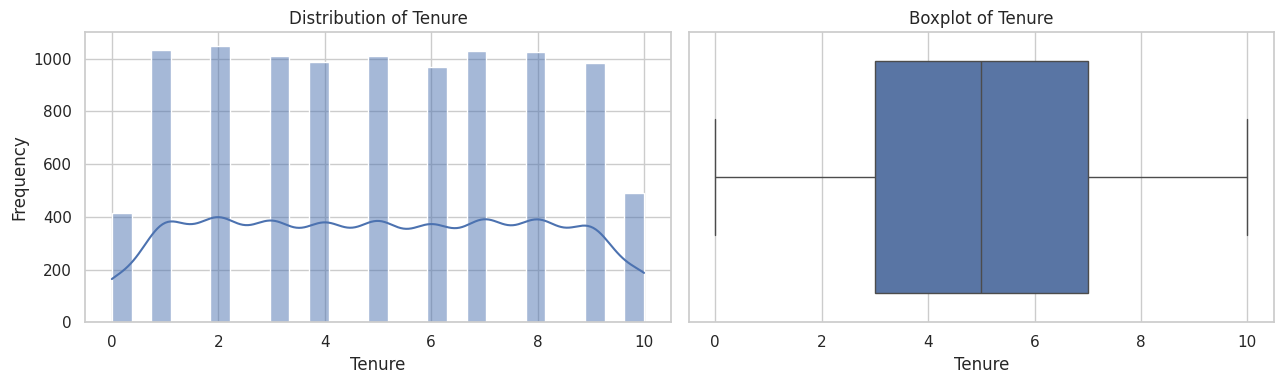

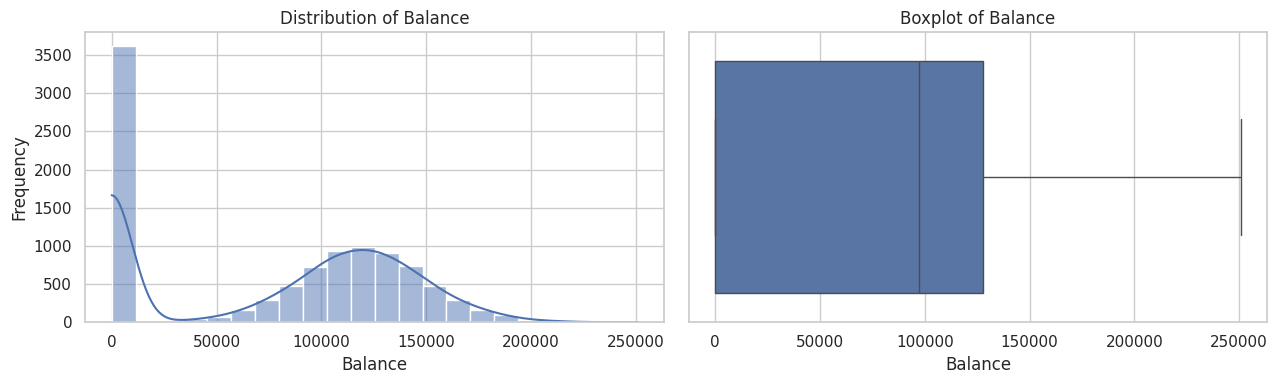

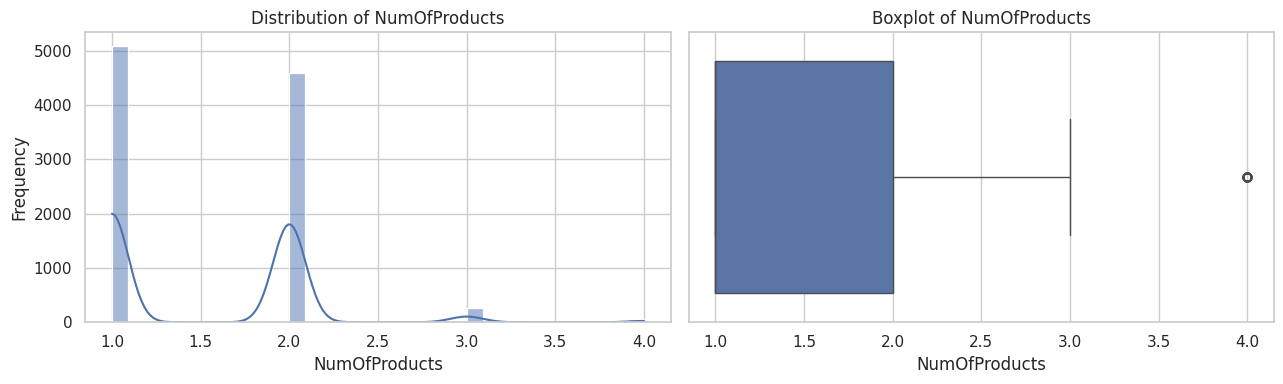

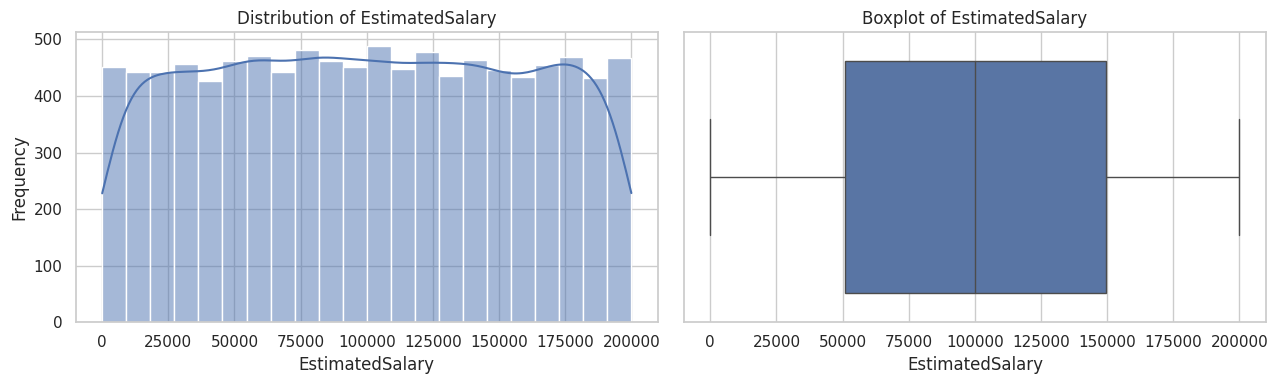

In [6]:
numerical_features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

for feature in numerical_features:

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # Histogram
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(f"Distribution of {feature}")
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel("Frequency")

    # Boxplot
    sns.boxplot(
        data=df,
        x=feature,
        ax=axes[1]
    )

    axes[1].set_title(f"Boxplot of {feature}")

    plt.tight_layout()
    plt.show()

In [7]:
features = [
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

for feature in features:
    print(f"\n{'=' * 50}")
    print(f"FEATURE: {feature}")
    print("=" * 50)

    print(df[feature].describe())

    print(f"\nSkewness: {df[feature].skew():.4f}")

    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = (
        (df[feature] < lower) |
        (df[feature] > upper)
    ).sum()

    print(f"IQR: {iqr:.2f}")
    print(f"Lower boundary: {lower:.2f}")
    print(f"Upper boundary: {upper:.2f}")
    print(f"Potential outliers: {outliers}")


FEATURE: Tenure
count    10000.000000
mean         5.012800
std          2.892174
min          0.000000
25%          3.000000
50%          5.000000
75%          7.000000
max         10.000000
Name: Tenure, dtype: float64

Skewness: 0.0110
IQR: 4.00
Lower boundary: -3.00
Upper boundary: 13.00
Potential outliers: 0

FEATURE: Balance
count     10000.000000
mean      76485.889288
std       62397.405202
min           0.000000
25%           0.000000
50%       97198.540000
75%      127644.240000
max      250898.090000
Name: Balance, dtype: float64

Skewness: -0.1411
IQR: 127644.24
Lower boundary: -191466.36
Upper boundary: 319110.60
Potential outliers: 0

FEATURE: NumOfProducts
count    10000.000000
mean         1.530200
std          0.581654
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max          4.000000
Name: NumOfProducts, dtype: float64

Skewness: 0.7456
IQR: 1.00
Lower boundary: -0.50
Upper boundary: 3.50
Potential outliers: 60

FEATURE: Est

In [8]:
print("TENURE DISTRIBUTION")
print(df["Tenure"].value_counts().sort_index())

print("\nNUMBER OF PRODUCTS DISTRIBUTION")
print(df["NumOfProducts"].value_counts().sort_index())

print("\nZERO BALANCE CUSTOMERS")
print((df["Balance"] == 0).sum())

print("\nNON-ZERO BALANCE CUSTOMERS")
print((df["Balance"] > 0).sum())

TENURE DISTRIBUTION
Tenure
0      413
1     1035
2     1048
3     1009
4      989
5     1012
6      967
7     1028
8     1025
9      984
10     490
Name: count, dtype: int64

NUMBER OF PRODUCTS DISTRIBUTION
NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

ZERO BALANCE CUSTOMERS
3617

NON-ZERO BALANCE CUSTOMERS
6383


### 4.1 Numerical Feature Analysis — Key Findings

The numerical univariate analysis revealed several characteristics of the customer dataset.

1. **CreditScore:** Scores are broadly concentrated around the middle of the observed range, with some potential lower-end outliers.

2. **Age:** The distribution is positively skewed, with most customers concentrated in the younger and middle-aged groups. Older observations are flagged as potential statistical outliers.

3. **Tenure:** Customer tenure is approximately symmetrically distributed, with a mean of 5.01 years and no potential outliers under the IQR method.

4. **Balance:** Approximately 36.17% of customers have zero balance. The mean balance is lower than the median, indicating that zero and lower balance observations influence the distribution.

5. **NumOfProducts:** Most customers use one or two products. Only 3.26% use three or four products. The distribution is positively skewed.

6. **EstimatedSalary:** The distribution is approximately symmetric, with mean and median values close to 100,000.

Potential outliers identified through the IQR method will not be automatically removed because statistical outliers do not necessarily represent invalid observations.

These findings describe the overall customer population. Their relationships with customer churn will be investigated separately during bivariate analysis.

In [9]:
categorical_features = [
    "Geography",
    "Gender",
    "HasCrCard",
    "IsActiveMember"
]

for feature in categorical_features:

    print(f"\n{'=' * 50}")
    print(f"FEATURE: {feature}")
    print("=" * 50)

    counts = df[feature].value_counts()

    percentages = (
        df[feature].value_counts(normalize=True) * 100
    )

    summary = pd.DataFrame({
        "Customer Count": counts,
        "Percentage": percentages
    })

    display(summary)


FEATURE: Geography


,Customer Count,Percentage
Geography,,
France,5014,50.14
Germany,2509,25.09
Spain,2477,24.77



FEATURE: Gender


,Customer Count,Percentage
Gender,,
Male,5457,54.57
Female,4543,45.43



FEATURE: HasCrCard


,Customer Count,Percentage
HasCrCard,,
1,7055,70.55
0,2945,29.45



FEATURE: IsActiveMember


,Customer Count,Percentage
IsActiveMember,,
1,5151,51.51
0,4849,48.49


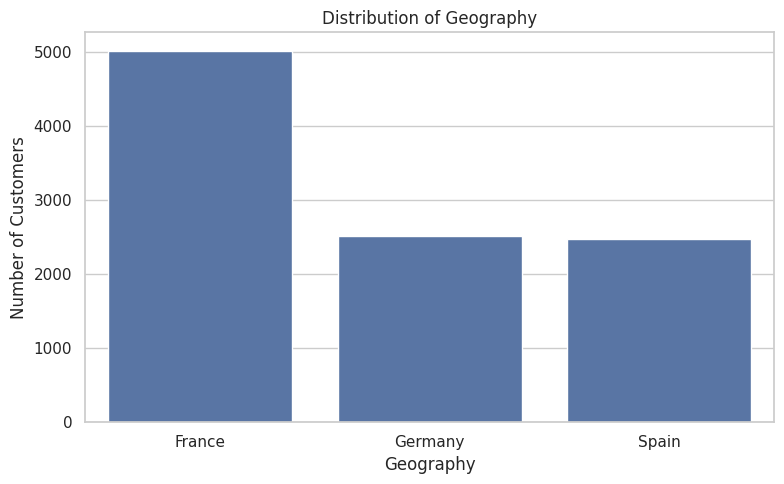

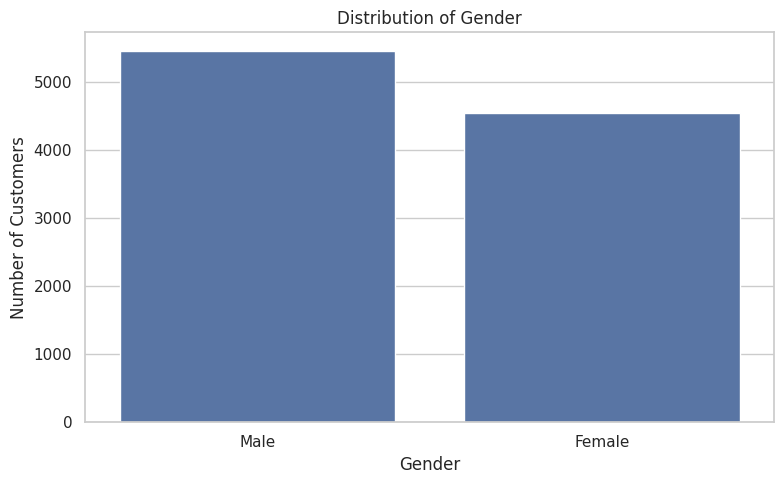

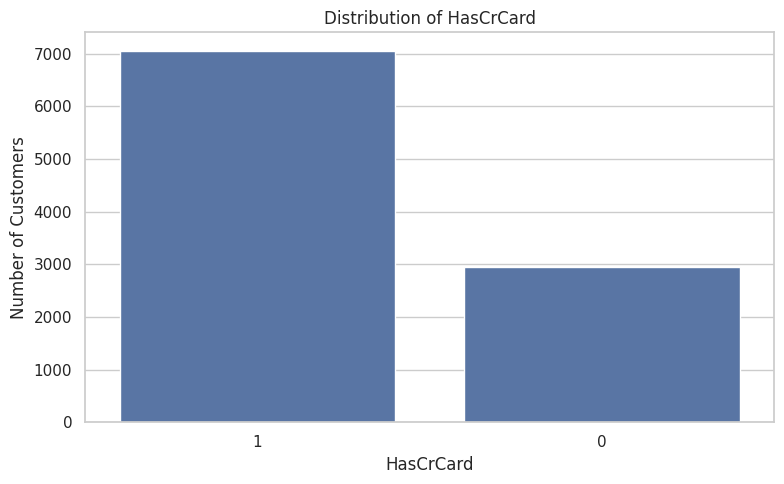

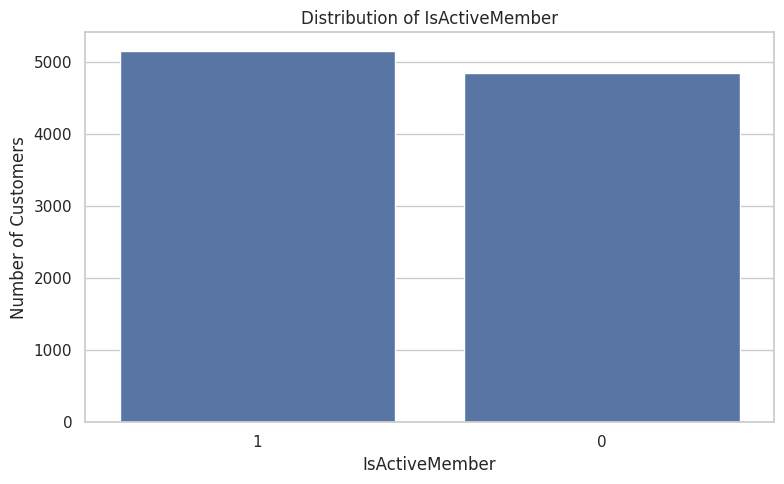

In [10]:
for feature in categorical_features:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=feature,
        order=df[feature].value_counts().index
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Customers")

    plt.tight_layout()
    plt.show()

In [11]:
categorical_features = [
    "Geography",
    "Gender",
    "HasCrCard",
    "IsActiveMember"
]

for feature in categorical_features:

    print(f"\n--- {feature} ---")

    counts = df[feature].value_counts().sort_index()

    percentages = (
        df[feature].value_counts(normalize=True).sort_index() * 100
    )

    for category in counts.index:
        print(
            f"{category}: {counts[category]} customers "
            f"({percentages[category]:.2f}%)"
        )


--- Geography ---
France: 5014 customers (50.14%)
Germany: 2509 customers (25.09%)
Spain: 2477 customers (24.77%)

--- Gender ---
Female: 4543 customers (45.43%)
Male: 5457 customers (54.57%)

--- HasCrCard ---
0: 2945 customers (29.45%)
1: 7055 customers (70.55%)

--- IsActiveMember ---
0: 4849 customers (48.49%)
1: 5151 customers (51.51%)


### 4.2 Categorical Feature Analysis — Key Findings

The categorical univariate analysis revealed the following characteristics:

1. **Geography:** France represents 50.14% of customers, while Germany and Spain account for 25.09% and 24.77%, respectively.

2. **Gender:** Male customers represent 54.57% of the dataset, compared with 45.43% female customers.

3. **HasCrCard:** Approximately 70.55% of customers own a credit card, while 29.45% do not.

4. **IsActiveMember:** Active and inactive customers are distributed relatively evenly, representing 51.51% and 48.49%, respectively.

These findings describe the composition of the customer population. They do not establish that any categorical feature causes or predicts churn. Relationships with the target variable will be investigated during bivariate analysis.

## 5. Bivariate Analysis

### 5.1 Geography vs. Customer Churn

This analysis investigates whether customer churn rates differ across geographical regions.

In [12]:
# Calculate customer count and churn rate by geography

geography_analysis = (
    df.groupby("Geography")["Exited"]
    .agg(
        Total_Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

geography_analysis["Churn_Rate"] *= 100

geography_analysis

,Total_Customers,Churned_Customers,Churn_Rate
Geography,,,
France,5014,810,16.154767
Germany,2509,814,32.443204
Spain,2477,413,16.673395


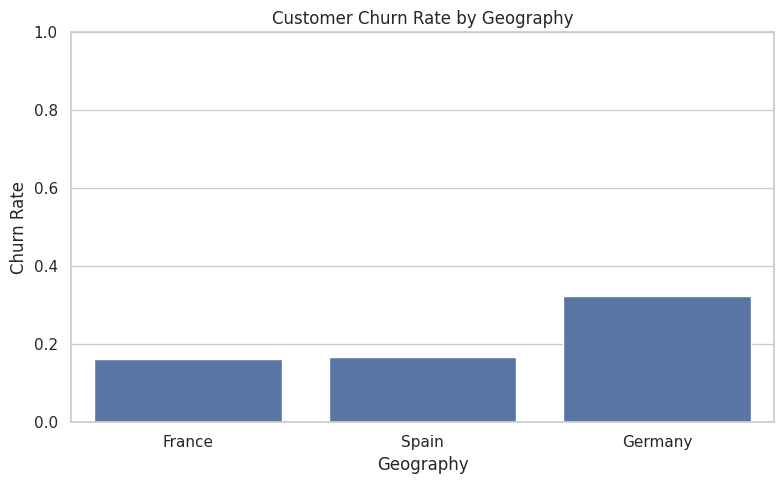

In [13]:
# Visualize churn rate by geography

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Geography",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Geography")
plt.xlabel("Geography")
plt.ylabel("Churn Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

### 5.2 Gender vs. Customer Churn

In [14]:
gender_analysis = (
    df.groupby("Gender")["Exited"]
    .agg(
        Total_Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

gender_analysis["Churn_Rate"] *= 100

gender_analysis

,Total_Customers,Churned_Customers,Churn_Rate
Gender,,,
Female,4543,1139,25.071539
Male,5457,898,16.455928


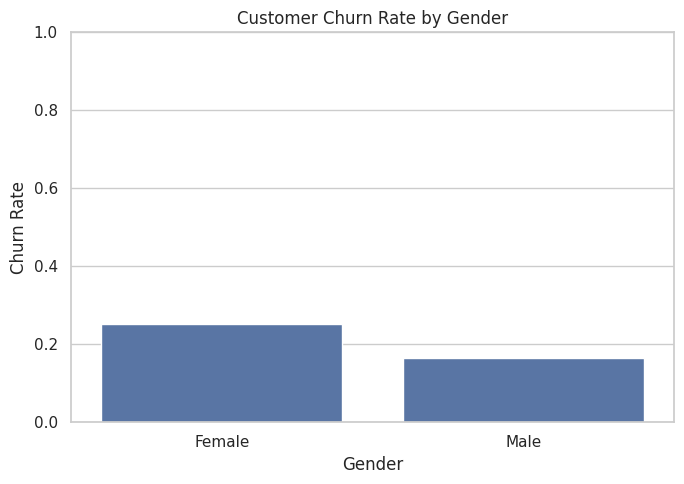

In [15]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Gender",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

### 5.3 Credit Card Ownership vs. Customer Churn

In [16]:
card_analysis = (
    df.groupby("HasCrCard")["Exited"]
    .agg(
        Total_Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

card_analysis["Churn_Rate"] *= 100

card_analysis

,Total_Customers,Churned_Customers,Churn_Rate
HasCrCard,,,
0,2945,613,20.814941
1,7055,1424,20.184266


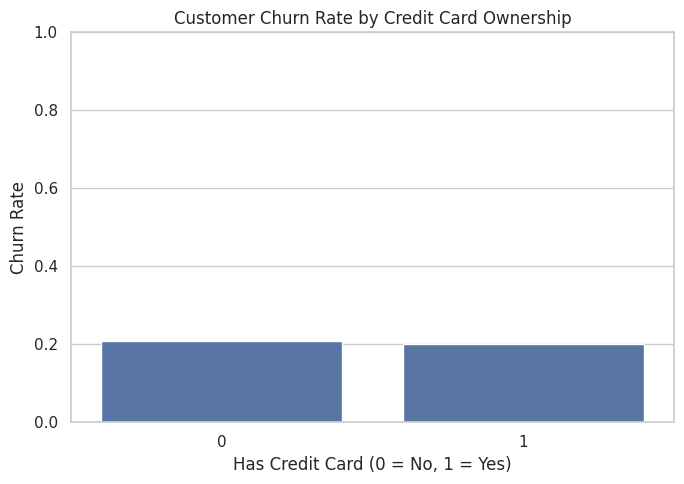

In [17]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="HasCrCard",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Credit Card Ownership")
plt.xlabel("Has Credit Card (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

### 5.4 Active Membership vs. Customer Churn

In [18]:
membership_analysis = (
    df.groupby("IsActiveMember")["Exited"]
    .agg(
        Total_Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

membership_analysis["Churn_Rate"] *= 100

membership_analysis

,Total_Customers,Churned_Customers,Churn_Rate
IsActiveMember,,,
0,4849,1302,26.850897
1,5151,735,14.269074


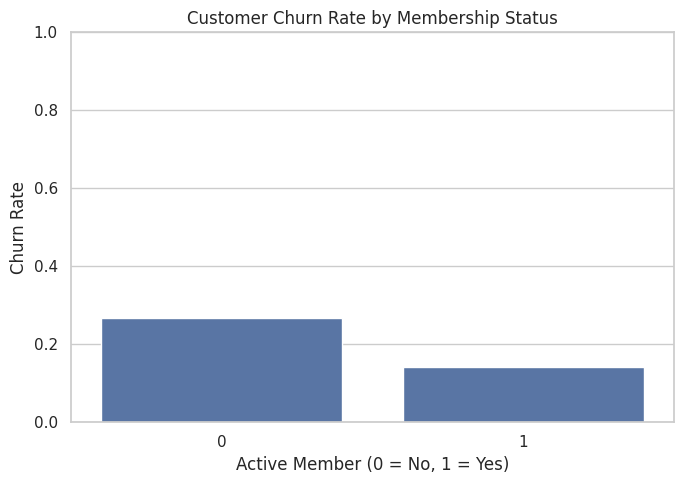

In [19]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="IsActiveMember",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Membership Status")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

### 5.5 Numerical Features vs. Customer Churn

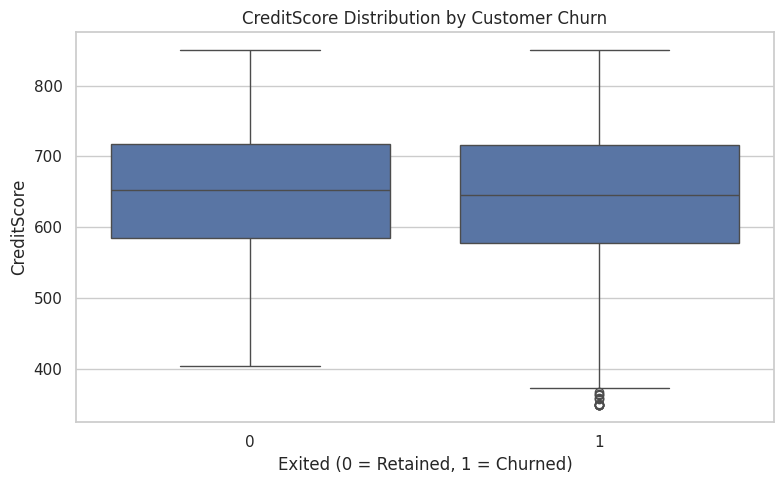

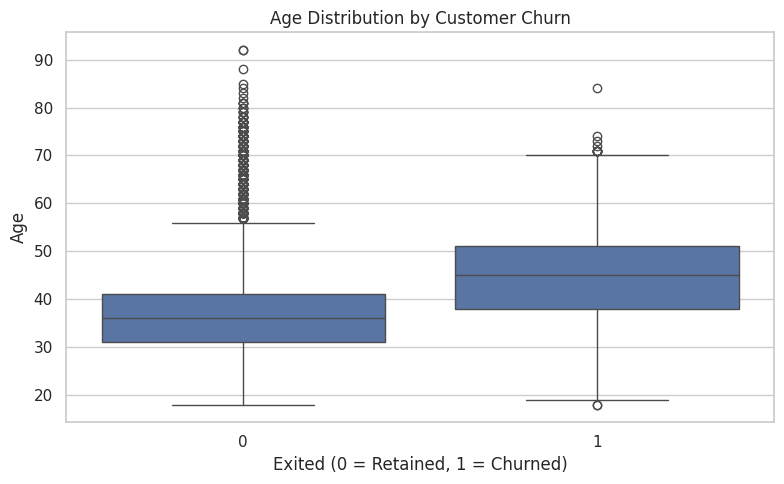

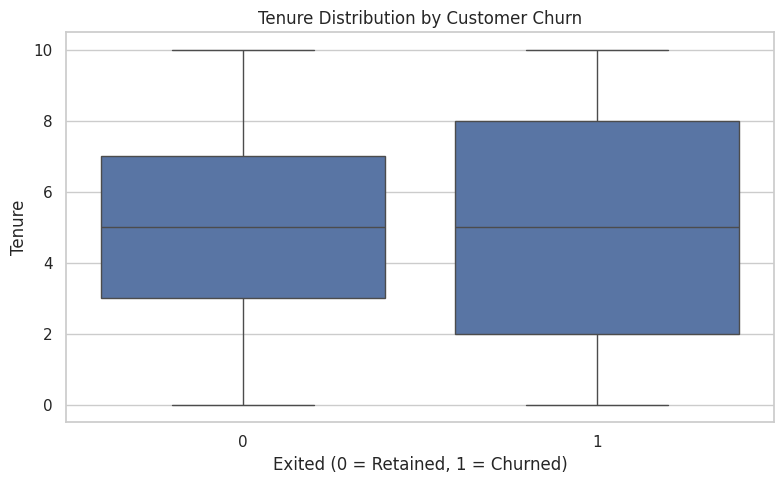

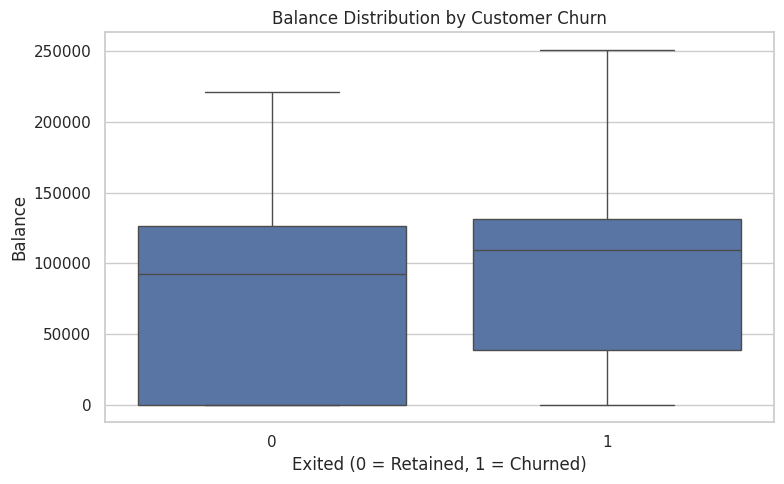

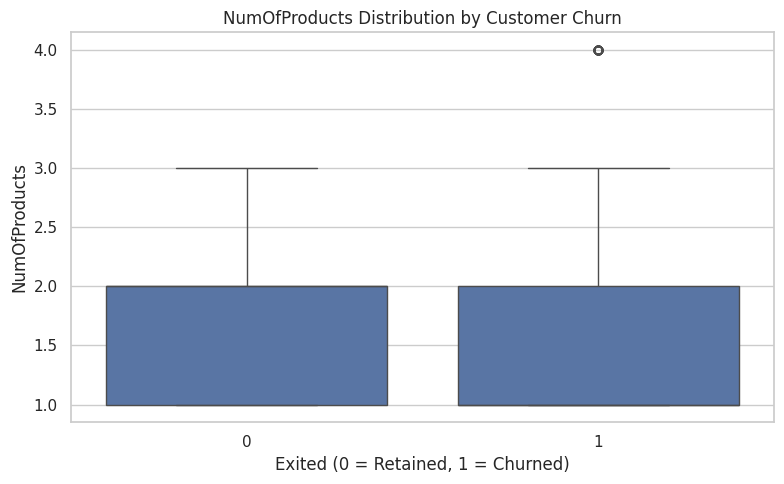

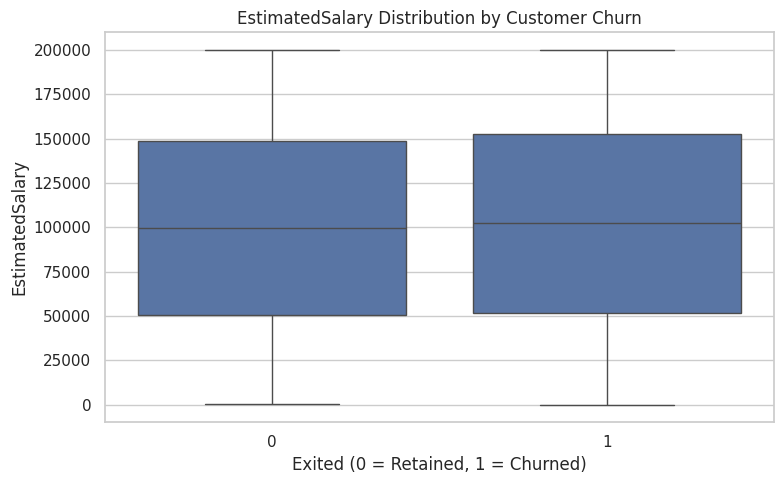

In [20]:
numerical_features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

for feature in numerical_features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="Exited",
        y=feature
    )

    plt.title(f"{feature} Distribution by Customer Churn")
    plt.xlabel("Exited (0 = Retained, 1 = Churned)")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

In [21]:
for feature in numerical_features:

    print(f"\n{'=' * 50}")
    print(f"FEATURE: {feature}")
    print("=" * 50)

    summary = (
        df.groupby("Exited")[feature]
        .agg(["count", "mean", "median", "std"])
    )

    summary.index = ["Retained", "Churned"]

    display(summary)


FEATURE: CreditScore


,count,mean,median,std
Retained,7963,651.853196,653.0,95.653837
Churned,2037,645.351497,646.0,100.321503



FEATURE: Age


,count,mean,median,std
Retained,7963,37.408389,36.0,10.125363
Churned,2037,44.837997,45.0,9.761562



FEATURE: Tenure


,count,mean,median,std
Retained,7963,5.033279,5.0,2.880658
Churned,2037,4.932744,5.0,2.936106


... (2 outputs left out)


FEATURE: NumOfProducts


,count,mean,median,std
Retained,7963,1.544267,2.0,0.509536
Churned,2037,1.475209,1.0,0.801521



FEATURE: EstimatedSalary


,count,mean,median,std
Retained,7963,99738.391772,99645.04,57405.586966
Churned,2037,101465.677531,102460.84,57912.418071


In [22]:
# Bivariate analysis: consolidated numerical results

categorical_features = [
    "Geography",
    "Gender",
    "HasCrCard",
    "IsActiveMember"
]

print("=" * 65)
print("CATEGORICAL FEATURES VS CUSTOMER CHURN")
print("=" * 65)

for feature in categorical_features:

    print(f"\n{feature}")

    result = (
        df.groupby(feature)["Exited"]
        .agg(
            Total_Customers="count",
            Churned_Customers="sum",
            Churn_Rate="mean"
        )
    )

    result["Churn_Rate"] *= 100

    print(result.round(2).to_string())


numerical_features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

print("\n" + "=" * 65)
print("NUMERICAL FEATURES VS CUSTOMER CHURN")
print("=" * 65)

for feature in numerical_features:

    print(f"\n{feature}")

    result = (
        df.groupby("Exited")[feature]
        .agg(["count", "mean", "median", "std"])
    )

    result.index = ["Retained", "Churned"]

    print(result.round(2).to_string())

CATEGORICAL FEATURES VS CUSTOMER CHURN

Geography
           Total_Customers  Churned_Customers  Churn_Rate
Geography                                                
France                5014                810       16.15
Germany               2509                814       32.44
Spain                 2477                413       16.67

Gender
        Total_Customers  Churned_Customers  Churn_Rate
Gender                                                
Female             4543               1139       25.07
Male               5457                898       16.46

HasCrCard
           Total_Customers  Churned_Customers  Churn_Rate
HasCrCard                                                
0                     2945                613       20.81
1                     7055               1424       20.18

IsActiveMember
                Total_Customers  Churned_Customers  Churn_Rate
IsActiveMember                                                
0                          4849               1

### 5.6 Multivariate Analysis

#### Geography and Active Membership vs. Customer Churn

In [23]:
# Churn rate by geography and active membership

geo_activity_analysis = (
    df.groupby(["Geography", "IsActiveMember"])["Exited"]
    .agg(
        Total_Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

geo_activity_analysis["Churn_Rate"] *= 100

geo_activity_analysis.round(2)

Total_Customers  Churned_Customers  Churn_Rate
Geography IsActiveMember                                                
France    0                          2423                512       21.13
          1                          2591                298       11.50
Germany   0                          1261                518       41.08
          1                          1248                296       23.72
Spain     0                          1165                272       23.35
          1                          1312                141       10.75

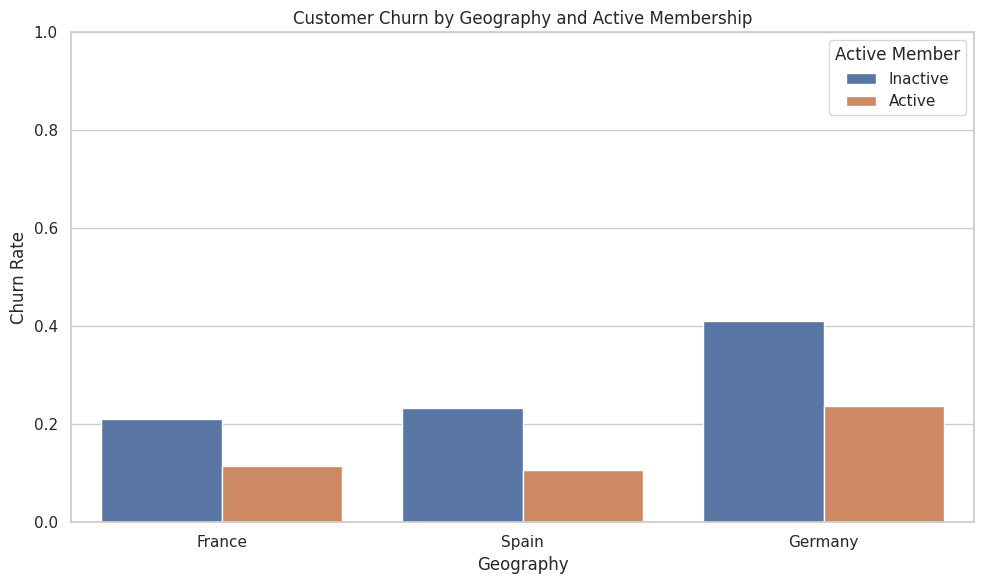

In [24]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Geography",
    y="Exited",
    hue="IsActiveMember",
    errorbar=None
)

plt.title("Customer Churn by Geography and Active Membership")
plt.xlabel("Geography")
plt.ylabel("Churn Rate")
plt.ylim(0, 1)

plt.legend(
    title="Active Member",
    labels=["Inactive", "Active"]
)

plt.tight_layout()
plt.show()

In [25]:
# Create age groups

age_bins = [17, 25, 35, 45, 55, 65, float("inf")]

age_labels = [
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "Above 65"
]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels
)

# Calculate churn rate by age group

age_group_analysis = (
    df.groupby("AgeGroup", observed=False)["Exited"]
    .agg(
        Total_Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

age_group_analysis["Churn_Rate"] *= 100

age_group_analysis.round(2)

,Total_Customers,Churned_Customers,Churn_Rate
AgeGroup,,,
18-25,611,46,7.53
26-35,3542,301,8.50
36-45,3736,733,19.62
46-55,1311,663,50.57
56-65,536,259,48.32
Above 65,264,35,13.26


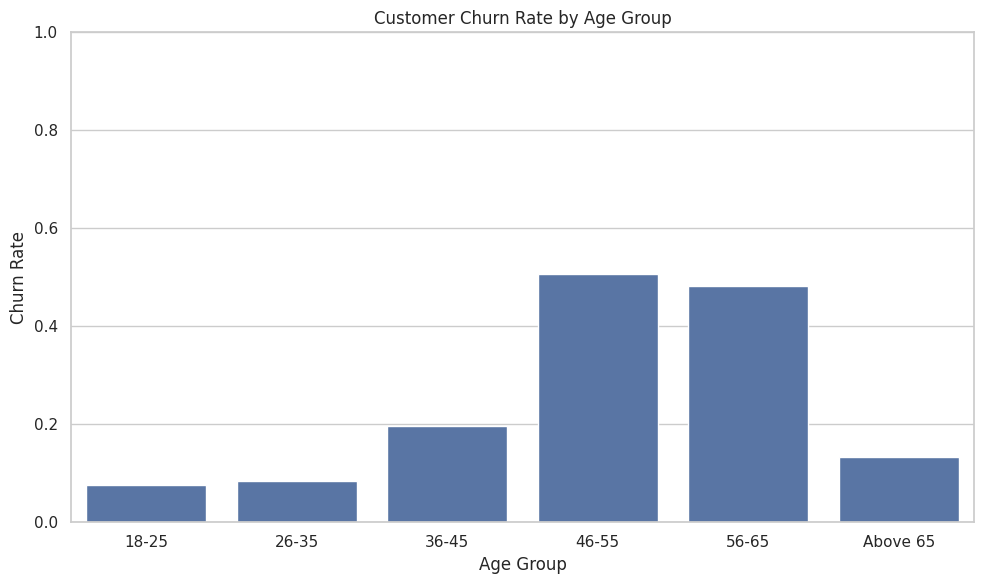

In [26]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="AgeGroup",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [27]:
product_analysis = (
    df.groupby("NumOfProducts")["Exited"]
    .agg(
        Total_Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

product_analysis["Churn_Rate"] *= 100

product_analysis.round(2)

,Total_Customers,Churned_Customers,Churn_Rate
NumOfProducts,,,
1,5084,1409,27.71
2,4590,348,7.58
3,266,220,82.71
4,60,60,100.00


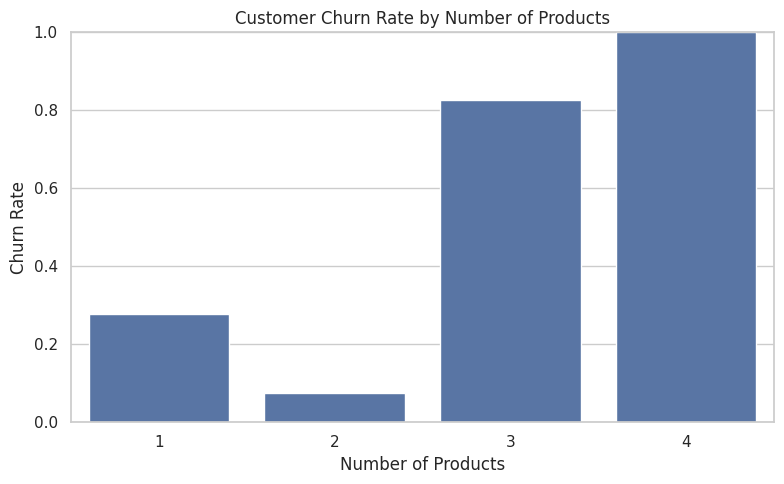

In [28]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="NumOfProducts",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [29]:
geo_age_analysis = (
    df.groupby(
        ["Geography", "AgeGroup"],
        observed=False
    )["Exited"]
    .mean()
    .mul(100)
    .unstack()
)

geo_age_analysis.round(2)

AgeGroup,18-25,26-35,36-45,46-55,56-65,Above 65
Geography,,,,,,
France,5.23,5.79,16.04,44.39,44.80,9.02
Germany,11.19,14.80,31.36,67.00,64.86,25.00
Spain,8.64,8.54,14.83,41.16,36.96,10.45


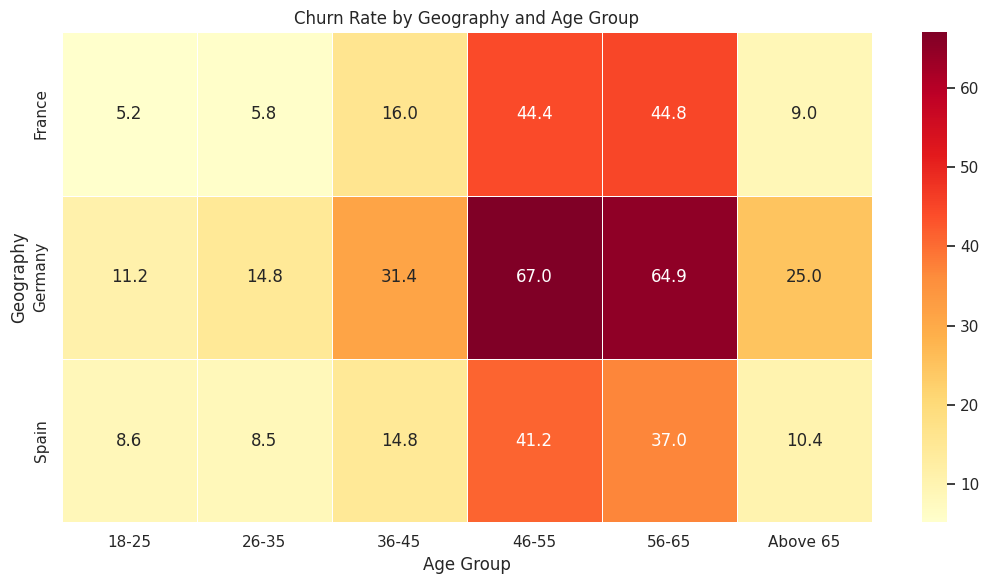

In [30]:
plt.figure(figsize=(11, 6))

sns.heatmap(
    geo_age_analysis,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Churn Rate by Geography and Age Group")
plt.xlabel("Age Group")
plt.ylabel("Geography")

plt.tight_layout()
plt.show()

In [31]:
correlation_features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

correlation_matrix = df[correlation_features].corr()

correlation_matrix.round(3)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
CreditScore,1.000,-0.004,0.001,0.006,0.012,-0.005,0.026,-0.001,-0.027
Age,-0.004,1.000,-0.010,0.028,-0.031,-0.012,0.085,-0.007,0.285
Tenure,0.001,-0.010,1.000,-0.012,0.013,0.023,-0.028,0.008,-0.014
Balance,0.006,0.028,-0.012,1.000,-0.304,-0.015,-0.010,0.013,0.119
NumOfProducts,0.012,-0.031,0.013,-0.304,1.000,0.003,0.010,0.014,-0.048
HasCrCard,-0.005,-0.012,0.023,-0.015,0.003,1.000,-0.012,-0.010,-0.007
IsActiveMember,0.026,0.085,-0.028,-0.010,0.010,-0.012,1.000,-0.011,-0.156
EstimatedSalary,-0.001,-0.007,0.008,0.013,0.014,-0.010,-0.011,1.000,0.012
Exited,-0.027,0.285,-0.014,0.119,-0.048,-0.007,-0.156,0.012,1.000


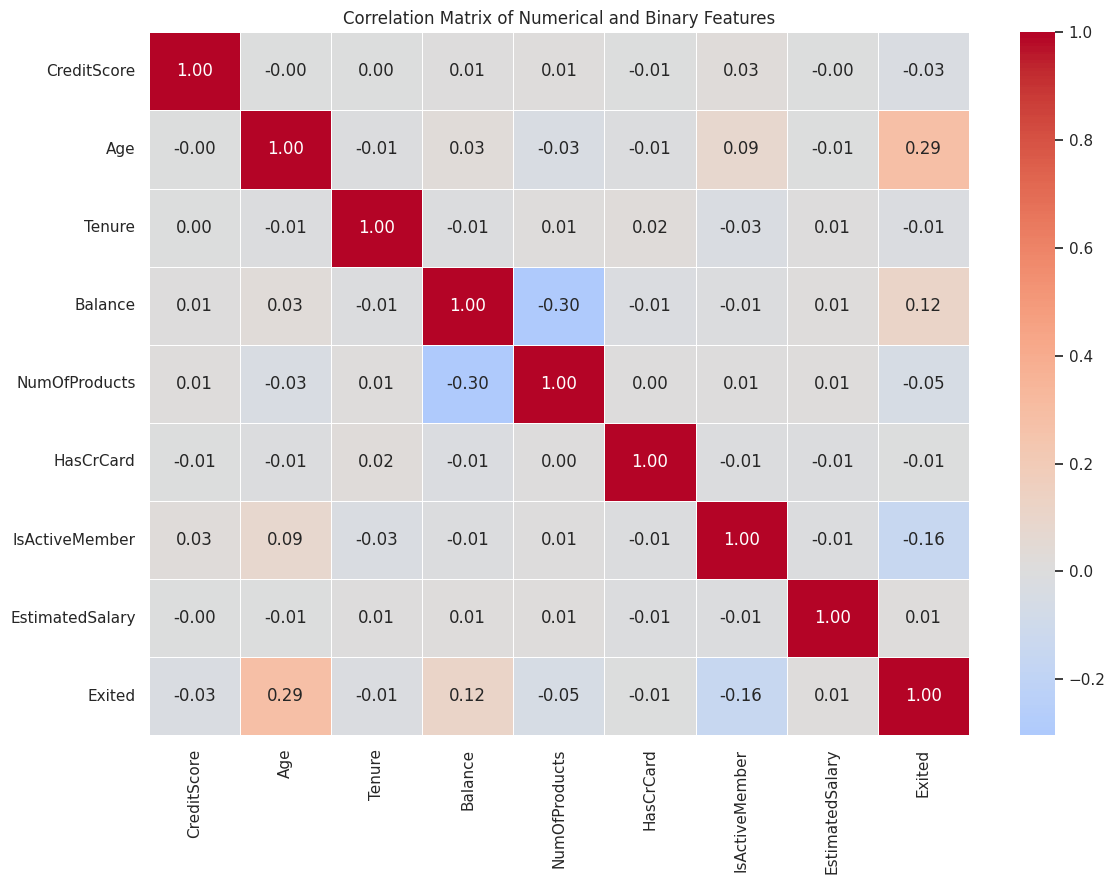

In [32]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical and Binary Features")

plt.tight_layout()
plt.show()

In [33]:
print("=" * 60)
print("1. GEOGRAPHY AND ACTIVE MEMBERSHIP VS CHURN")
print("=" * 60)
display(geo_activity_analysis.round(2))

print("\n" + "=" * 60)
print("2. AGE GROUP VS CHURN")
print("=" * 60)
display(age_group_analysis.round(2))

print("\n" + "=" * 60)
print("3. NUMBER OF PRODUCTS VS CHURN")
print("=" * 60)
display(product_analysis.round(2))

print("\n" + "=" * 60)
print("4. CORRELATION MATRIX")
print("=" * 60)
display(correlation_matrix.round(3))

1. GEOGRAPHY AND ACTIVE MEMBERSHIP VS CHURN


Total_Customers  Churned_Customers  Churn_Rate
Geography IsActiveMember                                                
France    0                          2423                512       21.13
          1                          2591                298       11.50
Germany   0                          1261                518       41.08
          1                          1248                296       23.72
Spain     0                          1165                272       23.35
          1                          1312                141       10.75


2. AGE GROUP VS CHURN


,Total_Customers,Churned_Customers,Churn_Rate
AgeGroup,,,
18-25,611,46,7.53
26-35,3542,301,8.50
36-45,3736,733,19.62
46-55,1311,663,50.57
56-65,536,259,48.32
Above 65,264,35,13.26



3. NUMBER OF PRODUCTS VS CHURN


,Total_Customers,Churned_Customers,Churn_Rate
NumOfProducts,,,
1,5084,1409,27.71
2,4590,348,7.58
3,266,220,82.71
4,60,60,100.00



4. CORRELATION MATRIX


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
CreditScore,1.000,-0.004,0.001,0.006,0.012,-0.005,0.026,-0.001,-0.027
Age,-0.004,1.000,-0.010,0.028,-0.031,-0.012,0.085,-0.007,0.285
Tenure,0.001,-0.010,1.000,-0.012,0.013,0.023,-0.028,0.008,-0.014
Balance,0.006,0.028,-0.012,1.000,-0.304,-0.015,-0.010,0.013,0.119
NumOfProducts,0.012,-0.031,0.013,-0.304,1.000,0.003,0.010,0.014,-0.048
HasCrCard,-0.005,-0.012,0.023,-0.015,0.003,1.000,-0.012,-0.010,-0.007
IsActiveMember,0.026,0.085,-0.028,-0.010,0.010,-0.012,1.000,-0.011,-0.156
EstimatedSalary,-0.001,-0.007,0.008,0.013,0.014,-0.010,-0.011,1.000,0.012
Exited,-0.027,0.285,-0.014,0.119,-0.048,-0.007,-0.156,0.012,1.000


## 6. Exploratory Data Analysis — Final Findings

### 6.1 Target Distribution

The dataset contains 10,000 customer records, of which 2,037 (20.37%) represent churned customers and 7,963 (79.63%) represent retained customers.

This indicates a moderate class imbalance. Consequently, model evaluation should consider precision, recall, F1-score, ROC-AUC and PR-AUC rather than relying exclusively on accuracy.

### 6.2 Categorical Feature Findings

- Geography: Germany has a churn rate of 32.44%, substantially higher than France (16.15%) and Spain (16.67%).
- Gender: Female customers have a churn rate of 25.07%, compared with 16.46% for male customers.
- Credit card ownership: Churn rates are relatively similar between customers with and without credit cards.
- Active membership: Inactive customers have a churn rate of 26.85%, compared with 14.27% for active customers.

### 6.3 Numerical Feature Findings

- Age: Churned customers have a higher mean age (44.84) than retained customers (37.41).
- Balance: Churned customers have a higher mean balance (91,108.54) than retained customers (72,745.30).
- Number of products: Churned customers have a lower median product count.
- CreditScore, Tenure and EstimatedSalary show relatively small differences in their group-level summary statistics.

### 6.4 Multivariate Findings

The relationship between active membership and churn remains visible across France, Germany and Spain. Inactive customers have higher observed churn rates in all three countries.

Age-group analysis reveals substantial variation in churn. The highest observed churn rates occur among customers aged 46–55 (50.57%) and 56–65 (48.32%).

Product-count analysis reveals a nonlinear pattern. Customers with three and four products have particularly high observed churn rates. However, these groups contain relatively few observations, especially the four-product category, which contains only 60 customers.

### 6.5 Correlation Findings

Among the included numerical and binary variables, Age has the strongest positive Pearson correlation with churn (+0.285), followed by Balance (+0.119).

IsActiveMember has a negative correlation with churn (-0.156).

The remaining features have relatively weak linear correlations with the target.

The correlation analysis does not include categorical variables such as Geography and Gender. Furthermore, correlation does not establish causation and cannot capture all nonlinear relationships.

### 6.6 Modeling Implications

The EDA suggests that Age, Geography, IsActiveMember, Balance and NumOfProducts deserve particular attention during model development.

Potential nonlinear relationships should be investigated using tree-based models alongside a Logistic Regression baseline.

All observations are exploratory. Feature importance, predictive performance and generalization must be established through appropriate training, validation and testing.

No observations have been removed solely because they were identified as statistical outliers, and the original raw dataset remains unchanged.